In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# load dataset
df = pd.read_csv("../data/bank.csv")

#display first 5 rows
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [2]:
print("dataset shape:")
print(df.shape)

print("\ncolumns:")
print(df.columns.tolist())

print("\ndataset information:")
df.info()

print("\nmissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

dataset shape:
(11162, 17)

columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']

dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 

In [3]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [4]:
print(df["deposit"].value_counts())

print("\nDeposit Percentage :")

print(df["deposit"].value_counts(normalize= True) * 100)

deposit
no     5873
yes    5289
Name: count, dtype: int64

Deposit Percentage :
deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64


In [5]:
print("Missing Values :")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values :
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0


In [6]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns :
    print(f"\n{col}")
    print(df[col].value_counts())


job
job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64

marital
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64

education
education
secondary    5476
tertiary     3689
primary      1500
unknown       497
Name: count, dtype: int64

default
default
no     10994
yes      168
Name: count, dtype: int64

housing
housing
no     5881
yes    5281
Name: count, dtype: int64

loan
loan
no     9702
yes    1460
Name: count, dtype: int64

contact
contact
cellular     8042
unknown      2346
telephone     774
Name: count, dtype: int64

month
month
may    2824
aug    1519
jul    1514
jun    1222
nov     943
apr     923
feb     776
oct     392
jan     344
sep     319
mar     276
dec     110
Name: count, dtype: int64

poutcome
p

/tmp/ipykernel_27844/3617426038.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [7]:
print(
    df.groupby("deposit")["age"].agg(
        ["count", "mean", "median", "min", "max"]
    )
)

         count       mean  median  min  max
deposit                                    
no        5873  40.837391    39.0   18   89
yes       5289  41.670070    38.0   18   95


In [8]:
print(
    df.groupby("deposit")["balance"].agg(
        ["mean", "median", "min", "max"]
    )
)

                mean  median   min    max
deposit                                  
no       1280.227141   414.0 -6847  66653
yes      1804.267915   733.0 -3058  81204


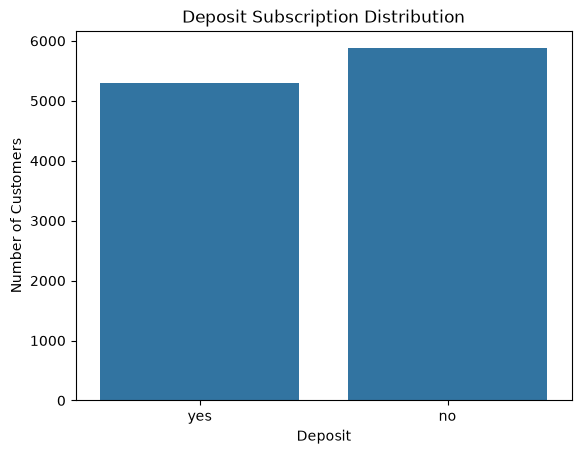

In [9]:
plt.Figure(figsize=(7, 5))

sns.countplot(
    data = df,
    x = "deposit"
)

plt.title("Deposit Subscription Distribution")
plt.xlabel("Deposit")
plt.ylabel("Number of Customers")

plt.show()

In [10]:
numerical_columns = df.select_dtypes(
    include="number"
).columns

for col in numerical_columns :
    print(f"\n{col}")
    print("Unique values :", df[col].nunique())
    print("Minimum :", df[col].min())
    print("Maximum :",df[col].max())



age
Unique values : 76
Minimum : 18
Maximum : 95

balance
Unique values : 3805
Minimum : -6847
Maximum : 81204

day
Unique values : 31
Minimum : 1
Maximum : 31

duration
Unique values : 1428
Minimum : 2
Maximum : 3881

campaign
Unique values : 36
Minimum : 1
Maximum : 63

pdays
Unique values : 472
Minimum : -1
Maximum : 854

previous
Unique values : 34
Minimum : 0
Maximum : 58


In [11]:
negative_balance = df[df["balance"]< 0]

print("Negative balance records :")
print(len(negative_balance))

print("\nPercentage :")
print(len(negative_balance)/ len(df) * 100)

Negative balance records :
688

Percentage :
6.163769933703637


In [12]:
print(df["pdays"].value_counts().head(10))

print("\nPdays equal to -1 :")
print((df["pdays"] == -1).sum())

print("\nPrevious campaign outcome :")
print(df["poutcome"].value_counts())

pdays
-1      8324
 92      106
 182      89
 91       84
 181      81
 183      73
 184      52
 94       42
 93       41
 95       39
Name: count, dtype: int64

Pdays equal to -1 :
8324

Previous campaign outcome :
poutcome
unknown    8326
failure    1228
success    1071
other       537
Name: count, dtype: int64


In [13]:
print(df["duration"].describe())

count    11162.000000
mean       371.993818
std        347.128386
min          2.000000
25%        138.000000
50%        255.000000
75%        496.000000
max       3881.000000
Name: duration, dtype: float64


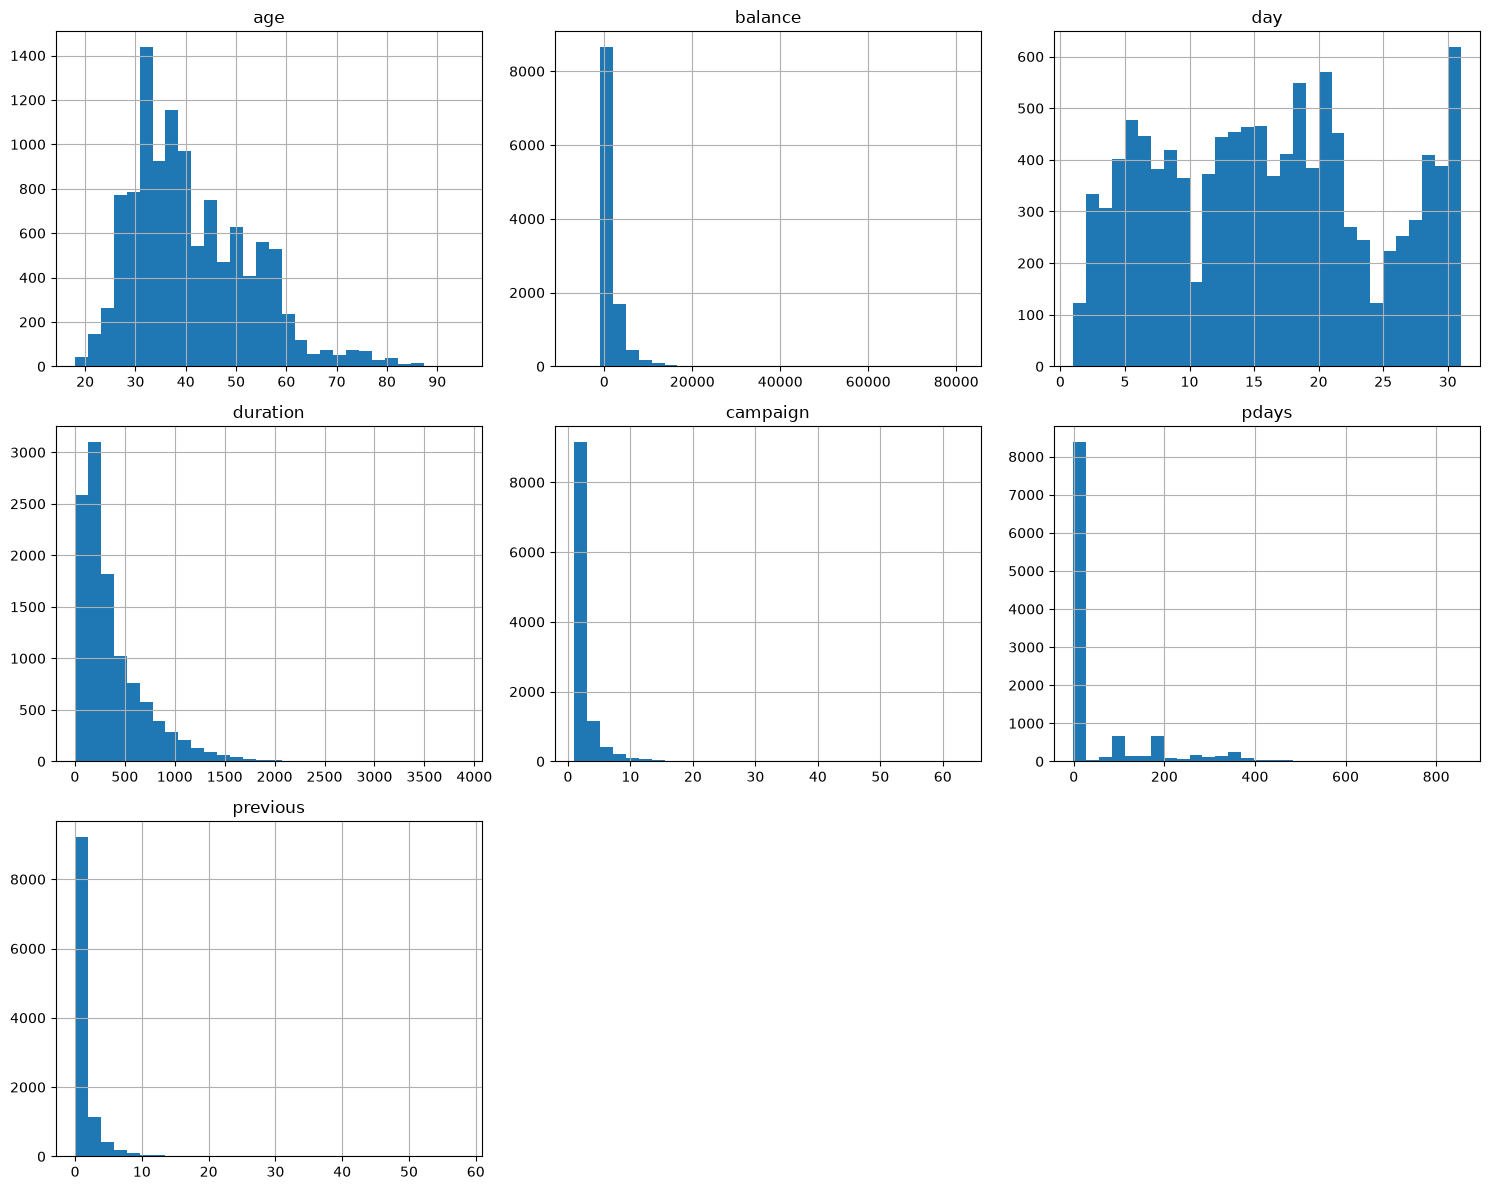

In [14]:
df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()
plt.show()

In [15]:
model_df = df.drop(
    columns=["duration"]
).copy()

print("Original shape :", df.shape)
print("Model data shape", model_df.shape)

model_df.head()

Original shape : (11162, 17)
Model data shape (11162, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,2,-1,0,unknown,yes


In [16]:
categorical_columns = model_df.select_dtypes(include=["object", "str"]).columns

print("categorical columns :")
print(categorical_columns)

print("\nNumber of categorical columns :")
print(len(categorical_columns))

categorical columns :
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='str')

Number of categorical columns :
10


In [17]:
for col in categorical_columns:
    print(f"\n{col}")
    print("Unique values :", model_df[col].nunique())
    print(model_df[col].unique())


job
Unique values : 12
<StringArray>
[       'admin.',    'technician',      'services',    'management',
       'retired',   'blue-collar',    'unemployed',  'entrepreneur',
     'housemaid',       'unknown', 'self-employed',       'student']
Length: 12, dtype: str

marital
Unique values : 3
<StringArray>
['married', 'single', 'divorced']
Length: 3, dtype: str

education
Unique values : 4
<StringArray>
['secondary', 'tertiary', 'primary', 'unknown']
Length: 4, dtype: str

default
Unique values : 2
<StringArray>
['no', 'yes']
Length: 2, dtype: str

housing
Unique values : 2
<StringArray>
['yes', 'no']
Length: 2, dtype: str

loan
Unique values : 2
<StringArray>
['no', 'yes']
Length: 2, dtype: str

contact
Unique values : 3
<StringArray>
['unknown', 'cellular', 'telephone']
Length: 3, dtype: str

month
Unique values : 12
<StringArray>
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb', 'mar', 'apr',
 'sep']
Length: 12, dtype: str

poutcome
Unique values : 4
<StringArray>
['u

In [18]:
x = model_df.drop(columns=["deposit"])
y = model_df["deposit"].map({
    "no" :0,
    "yes" :1
})


In [19]:
categorical_columns = x.select_dtypes(
    include=["object", "str"]
).columns

print(categorical_columns)

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='str')


In [20]:
x = pd.get_dummies(
    x,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Encoded features shape :", x.shape)
x.head()

Encoded features shape : (11162, 41)


,age,balance,day,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,59,2343,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
1,56,45,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
2,41,1270,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
3,55,2476,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
4,54,184,5,2,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1


In [21]:
print("Missing values :", x.isnull().sum().sum())

print("Non-numeric columns :")
print(x.select_dtypes(exclude="number").columns)

print("Target missing values :", y.isnull().sum())

print("Final x shape :", x.shape)
print("Final y shape :", y.shape)

Missing values : 0
Non-numeric columns :
Index([], dtype='str')
Target missing values : 0
Final x shape : (11162, 41)
Final y shape : (11162,)


In [22]:
from sklearn.model_selection import train_test_split

In [23]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
print("x_train:", x_train.shape)
print("x_test", x_test.shape)

print("y_train", y_train.shape)
print("y_test", y_test.shape)

x_train: (8929, 41)
x_test (2233, 41)
y_train (8929,)
y_test (2233,)


In [25]:
print("Training target distribution :")
print(y_train.value_counts(normalize=True)* 100)

print("\nTesting target distribution :")
print(y_test.value_counts(normalize=True)* 100)


Training target distribution :
deposit
0    52.615074
1    47.384926
Name: proportion, dtype: float64

Testing target distribution :
deposit
0    52.619794
1    47.380206
Name: proportion, dtype: float64


In [26]:
print("Training records:", len(x_train))
print("Testing records:", len(x_test))

print("Total records:", len(x_train) + len(x_test))

Training records: 8929
Testing records: 2233
Total records: 11162


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix

In [28]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [29]:
log_model.fit(x_train, y_train)

/home/alii/miniconda3/envs/ccanalysis/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [30]:
y_pred = log_model.predict(x_test)

In [31]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage :", accuracy * 100)

Accuracy: 0.6995073891625616
Accuracy percentage : 69.95073891625616


In [32]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Deposit", "Deposit"]
))

              precision    recall  f1-score   support

  No Deposit       0.68      0.82      0.74      1175
     Deposit       0.74      0.56      0.64      1058

    accuracy                           0.70      2233
   macro avg       0.71      0.69      0.69      2233
weighted avg       0.71      0.70      0.69      2233



In [33]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[966 209]
 [462 596]]


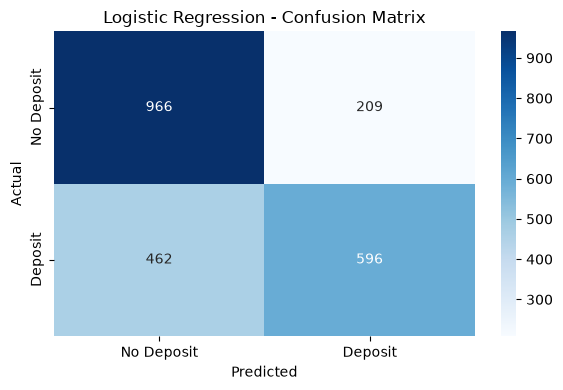

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Deposit", "Deposit"],
    yticklabels=["No Deposit", "Deposit"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()

In [35]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [36]:
log_model_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter= 3000,
        random_state=42
    ))
])

In [37]:
log_model_scaled.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](41,)","['age','balance','day',...,'poutcome_other','poutcome_success', 'poutcome_unknown']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,41
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [38]:
y_pred_scaled = log_model_scaled.predict(x_test)

In [39]:
accuracy_scaled = accuracy_score(y_test, y_pred_scaled)

print("accuracy", accuracy_scaled)
print("accuracy percentage", accuracy_scaled * 100)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_scaled,
    target_names=["No Deposit","Deposit"]
))

print("\nConfusion Matrix")
cm_scaled = confusion_matrix(y_test, y_pred_scaled)
print(cm_scaled)

accuracy 0.6950291088222122
accuracy percentage 69.50291088222123

Classification Report:
              precision    recall  f1-score   support

  No Deposit       0.67      0.82      0.74      1175
     Deposit       0.73      0.56      0.64      1058

    accuracy                           0.70      2233
   macro avg       0.70      0.69      0.69      2233
weighted avg       0.70      0.70      0.69      2233


Confusion Matrix
[[958 217]
 [464 594]]


In [40]:
print(
    "Number of iterations",
    log_model_scaled.named_steps["model"].n_iter_
)

Number of iterations [16]


In [41]:
print("Original Logistic Regression:")
print("Accuracy:", accuracy)

print("\nScaled Logistic Regression")
print("Accuracy:", accuracy_scaled)

Original Logistic Regression:
Accuracy: 0.6995073891625616

Scaled Logistic Regression
Accuracy: 0.6950291088222122


In [42]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [43]:
tree_model = DecisionTreeClassifier(
    max_depth= 5,
    random_state=42
)

In [44]:
tree_model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [45]:
y_pred_tree = tree_model.predict(x_test)

In [46]:
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy", tree_accuracy)
print("Accuracy percentage", tree_accuracy * 100)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["No Deposit","Deposit"]
))

print("\nConfusion Matrix")
cm_tree = confusion_matrix(y_test, y_pred_tree)
print(cm_tree)

Decision Tree Accuracy 0.6842812360053739
Accuracy percentage 68.42812360053739

Classification Report:
              precision    recall  f1-score   support

  No Deposit       0.67      0.80      0.73      1175
     Deposit       0.71      0.56      0.63      1058

    accuracy                           0.68      2233
   macro avg       0.69      0.68      0.68      2233
weighted avg       0.69      0.68      0.68      2233


Confusion Matrix
[[937 238]
 [467 591]]


In [47]:
from sklearn.ensemble import RandomForestClassifier

In [48]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [49]:
rf_model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [50]:
y_pred_rf = rf_model.predict(x_test)

In [51]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy", rf_accuracy)
print("Accuracy percentage", rf_accuracy * 100)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Deposit","Deposit"]
))

print("\nConfusion Matrix")
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

Random Forest Accuracy 0.7268248992386923
Accuracy percentage 72.68248992386923

Classification Report:
              precision    recall  f1-score   support

  No Deposit       0.70      0.85      0.77      1175
     Deposit       0.78      0.59      0.67      1058

    accuracy                           0.73      2233
   macro avg       0.74      0.72      0.72      2233
weighted avg       0.74      0.73      0.72      2233


Confusion Matrix
[[999 176]
 [434 624]]


In [52]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression" : y_pred,
    "Logistic Regression Scaled" : y_pred_scaled,
    "Decision Tree" : y_pred_tree,
    "Random Forest" : y_pred_rf
}

results = []

for name, precisions in models.items():
    results.append({
        "Model" : name,
        "Accuracy" : accuracy_score(y_test, precisions),
        "Precision" : precision_score(y_test, precisions),
        "Recall" : recall_score(y_test, precisions),
        "F1-score" : f1_score(y_test, precisions)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

results_df = results_df.round(3)

results_df

,Model,Accuracy,Precision,Recall,F1-score
3,Random Forest,0.727,0.780,0.590,0.672
0,Logistic Regression,0.700,0.740,0.563,0.640
1,Logistic Regression Scaled,0.695,0.732,0.561,0.636
2,Decision Tree,0.684,0.713,0.559,0.626


In [53]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [54]:
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [55]:
param_grid = {
    "n_estimators" : [100, 200],
    "max_depth" : [5, 10, 15, None],
    "min_samples_split" : [2, 5, 10]
}

In [56]:
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

In [57]:
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/home/alii/miniconda3/envs/ccanalysis/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_searc

In [58]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation F1:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': None, 'min_samples_split': 10, 'n_estimators': 200}

Best Cross Validation F1:
0.6952103238091893


In [59]:
best_rf_model = grid_search.best_estimator_

y_pred_best_rf = best_rf_model.predict(x_test)

print("Tuned Random Forest Accuracy:")
print(accuracy_score(y_test, y_pred_best_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best_rf,
    target_names=["No Deposit", "Deposit"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_rf))

Tuned Random Forest Accuracy:
0.729511867442902

Classification Report:
              precision    recall  f1-score   support

  No Deposit       0.71      0.83      0.76      1175
     Deposit       0.76      0.62      0.69      1058

    accuracy                           0.73      2233
   macro avg       0.74      0.72      0.72      2233
weighted avg       0.73      0.73      0.73      2233


Confusion Matrix:
[[971 204]
 [400 658]]


In [60]:
feature_importance = pd.DataFrame({
    "Feature" : x_train.columns,
    "Importance": best_rf_model.feature_importances_ 
})

feature_importance = feature_importance.sort_values(
    by= "Importance",
    ascending=False
)

feature_importance.head(5)

,Feature,Importance
1,balance,0.135437
0,age,0.117004
2,day,0.106105
39,poutcome_success,0.065082
26,contact_unknown,0.056697


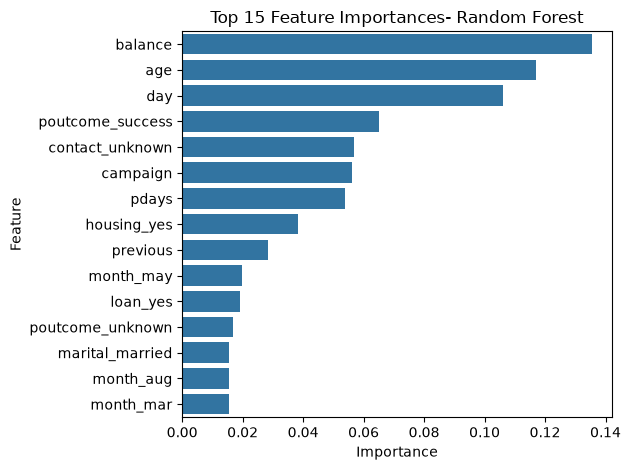

In [61]:
plt.Figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances- Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [62]:
from sklearn.inspection import permutation_importance

In [63]:
permutation_result = permutation_importance(
    best_rf_model,
    x_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

/home/alii/miniconda3/envs/ccanalysis/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/alii/miniconda3/envs/ccanalysis/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/alii/miniconda3/envs/ccanalysis/lib/python3.15/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/alii/miniconda3/envs/c

In [64]:
permutation_df = pd.DataFrame({
    "Feature": x_test.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print(permutation_df.head(15).to_string(index=False))

         Feature  Importance      Std
 contact_unknown    0.034126 0.002958
       month_oct    0.009544 0.001646
     housing_yes    0.007087 0.004416
poutcome_success    0.007023 0.003324
         balance    0.006620 0.005730
       month_mar    0.005403 0.002045
        loan_yes    0.005390 0.001698
       month_jan    0.004611 0.000944
        campaign    0.004024 0.003902
             age    0.002695 0.005149
       month_nov    0.002626 0.001515
poutcome_unknown    0.001357 0.002236
        previous    0.000912 0.002268
       month_jul    0.000826 0.003204
   job_housemaid    0.000777 0.001031


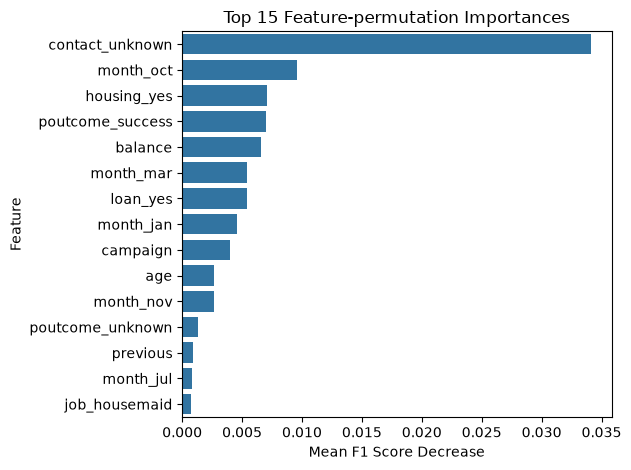

In [65]:
plt.Figure(figsize=(10, 7))

sns.barplot(
    data=permutation_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature-permutation Importances")
plt.xlabel("Mean F1 Score Decrease")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()